In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem1

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
env = problem1.environment(sigma_s = 1e-1)

In [3]:
np.random.seed(123)
dim = 2
order = 2

F = ta.sig_to_tensor([-2.0, 4.0, 1.1535923750750303, -12.000000000000014, 2.616165724745015, 4.305388525705165, 0.8287890137339372], dim, order=2)
strag_sig = problem1.sig_strag_dot(F, order = 2)

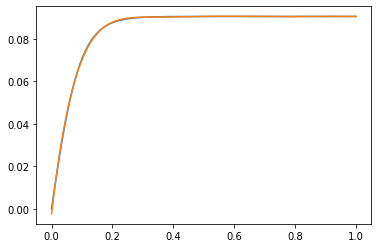

In [4]:
p_coef = np.polyfit(env.timesteps, env.V_alpha, deg = 7)
V_alpha_poly_fit = np.polyval(p_coef, env.timesteps)
plt.plot(env.timesteps, env.V_alpha)
plt.plot(env.timesteps, V_alpha_poly_fit)

In [5]:
p_coef_reversed = p_coef[::-1]

In [10]:
trunc_lev = 3
trunc_lev_1 = 5

f_s = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
for k in range(len(p_coef_reversed)):
    word_tensor = ta.word(word,dim)
    f_s += word_tensor*p_coef_reversed[k]
    word = (0,) + word
exp_a1 = (ta.word((0,),dim)*env.a1).exp()
f_s = f_s*exp_a1
f_s = f_s*(ta.word((0,),dim)*env.b1)
f_s += ta.word((1,),dim)*env.sigma_s
f_s += ta.word((1,),dim)*env.b0
f_s += F*(ta.word((0,),dim)*env.b2)
f_s += ta.word((),dim)*env.S0 
f_s = f_s.truncate(trunc_lev)

f_alpha = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
for k in range(len(p_coef_reversed)):
    word_tensor = ta.word(word,dim)
    f_alpha += word_tensor*p_coef_reversed[k]
    word = (0,) + word
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev_1)
f_alpha = f_alpha*exp_a1
f_alpha = f_alpha.truncate(trunc_lev_1)

In [7]:
nsims = 10

env.simulate(nsims, strag_sig)

In [11]:
f_s_sig = problem1.sig_strag_dot(f_s, order = trunc_lev)
f_alpha_sig = problem1.sig_strag_dot(f_alpha, order = trunc_lev_1)

S_sig = np.zeros((env.Nt+1,nsims))
alpha_hat_sig = np.zeros((env.Nt+1,nsims))

for it in range(env.Nt+1):
    S_sig[it,:] = f_s_sig(env,it)
    alpha_hat_sig[it,:] = f_alpha_sig(env,it)
    #S_sig[it,:] = strag_sig(env,it)

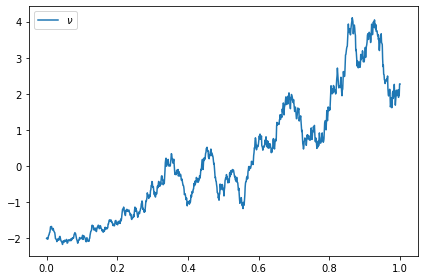

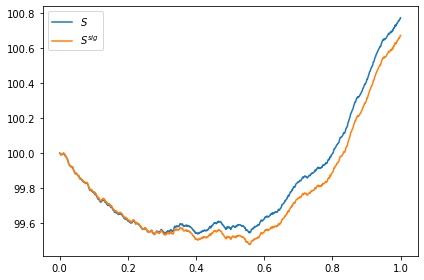

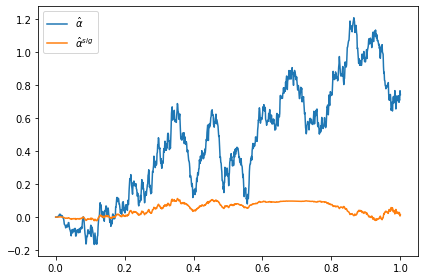

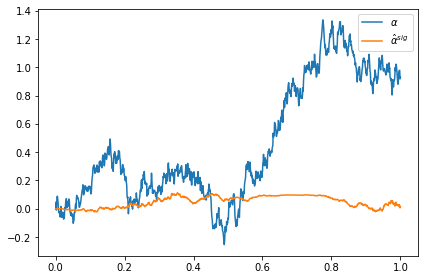

In [12]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()